# Field-of-view (FoV) predictor $f_\theta$, order 5: video `drive`

Given where a viewer was looking during the last five 5-second steps of a 360° video, this notebook trains a small
convolutional network to predict which tiles of the video will be in the viewer's field of view **5 seconds later**.
After training, the weights $\theta$ are saved to a single `.pt` file, the pretrained predictor used by the VAE.

## What the notebook does

1. **Loads the data.** For every viewer, the tile CSV is turned into a 10×20 binary map (1 = tile is in the viewer's FoV)
   sampled once every 5 s.
2. **Builds training pairs.** Five consecutive maps are the input, the next map is the target.
3. **Trains $f_\theta$** with plain gradient descent for 494 epochs. Each epoch uses a random group of 10 viewers.
   Figures show the viewers' actual FoV maps (section 2) and the predicted maps and crowd heatmap (section 4).
4. **Evaluates it** with the RMSE on all viewers and on a held-out group, next to two naive baselines.
5. **Saves** the trained weights to `predictor_weights_drive.pt`.
6. **Loads the pretrained predictor** from the `.pt` file, as the VAE will.

## Folder layout and files

```
predictor_vae/
├── dataset/360dataset/sensory/tile/   input: <video>/<prefix>_<user>_tile.csv per viewer
└── predictor/drive/
    ├── fov_predictor_drive.ipynb         this notebook (run it with predictor/drive/ as the working directory)
    ├── predictor_weights_drive.pt   output: the trained weights (written by this notebook)
    └── figures/                         output: PNGs of the plots in sections 2 and 4
```

| file | used by | what it is |
|---|---|---|
| `../dataset/360dataset/sensory/tile/drive/drive_user*_tile.csv` | training only | tile numbers inside each of the 50 viewers' FoV, per video frame |
| `predictor_weights_drive.pt` | any downstream notebook | trained $\theta$ plus the settings needed to rebuild the network |

## Setup

```bash
python3 -m venv .venv
.venv/bin/pip install -r requirements.txt
```

Then open this notebook with the `.venv` interpreter.
```bash
source .venv/bin/activate
```

In [1]:
import os, re, glob, time, random
from dataclasses import dataclass, asdict

import numpy as np
import pandas as pd
import torch
from torch import nn

print("PyTorch:", torch.__version__)

# Paths are relative to this notebook's folder (run with predictor/ as the working directory):
#   ../../dataset/360dataset/sensory/tile/   input:  one tile CSV per viewer
#   ./predictor_weights_drive.pt          output: the saved checkpoint
DATA_ROOT = os.path.join("..", "..", "dataset", "360dataset")
OUT_DIR   = "."

assert os.path.isdir(os.path.join(DATA_ROOT, "sensory", "tile")), (
    f"no sensory/tile under {DATA_ROOT}; run the notebook with predictor/drive/ as the working directory")
os.makedirs(OUT_DIR, exist_ok=True)
WEIGHTS_FILE = os.path.join(OUT_DIR, "predictor_weights_drive.pt")

DEVICE = torch.device("cpu")
torch.use_deterministic_algorithms(True)

print("DATA_ROOT =", DATA_ROOT)
print("outputs   ->", OUT_DIR)


PyTorch: 2.15.0+cpu


DATA_ROOT = ../../dataset/360dataset
outputs   -> .


## 1. Settings and notation

All hyper-parameters live in the `Cfg` dataclass below. The table explains how the notation in the code maps to the
training procedure.

| step | what it means here |
|---|---|
| users | $\mathcal{U}$ = the 50 viewers of the video, $u \in \mathcal{U}$. **All 50 are used for training.** |
| 1 video | one 60 s video at 30 fps (1800 frames), chosen in `Cfg.video` |
| 1 sample per 5 s | $G_{u,k} \in \{0,1\}^{W\times H}$ = viewer $u$'s tile map ($W=20$, $H=10$) of the **single frame** at $5k$ s, for $k=1..12$ |
| combined frame | $F_k = \frac{1}{\lvert\mathcal{U}\rvert}\sum_{u\in\mathcal{U}} G_{u,k} \in [0,1]^{W\times H}$ (the crowd's average, used at test time) |
| order $n=5$ | $\hat G_{u,k} = f_\theta(G_{u,k-n}, \dots, G_{u,k-2}, G_{u,k-1})$: five past maps in, one predicted map out |
| pairs | $12-n = 7$ per viewer, so $50 \times 7 = 350$ in all |
| one epoch | draw **10 of the 50 viewers at random** ($\binom{50}{10}$ possible groups), take their $10\times 7 = 70$ pairs, make **one** gradient step on them |
| video per epoch | $10 \times 7 \times 5\,\text{s} = 350\,\text{s}$ |
| budget | 48 h = 172,800 s $\Rightarrow \lceil 172800/350 \rceil = 494$ epochs (172,900 s) |
| loss | $J(\theta) = \lVert \hat G_{u,k} - G_{u,k} \rVert_2^2$, averaged over the epoch's 70 pairs |
| update | $\theta^{(e+1)} \leftarrow \theta^{(e)} - \eta_e\, \partial J/\partial\theta$ (plain gradient descent, one step per epoch) |
| learning rate | $\eta_e = a/(b+e)$ |
| test | one more random group of 10 viewers that is **not** any epoch's group; RMSE on its 70 pairs |

The loss is called $J$ because $L$ is already used in the methodology for the number of SVC layers.

In [2]:
@dataclass
class Cfg:
    video: str = "drive"     # the ONE video (name of its predictor)
    folder: str = "drive"    # its folder under sensory/tile/
    prefix: str = "drive"     # filename prefix of its CSVs: <prefix>_userNN_tile.csv
    fps: int = 30
    video_seconds: int = 60
    sample_every_s: int = 5     # 1 sample G_{u,k} per 5 s  -> 12 samples
    n: int = 5                  # predictor order: G_{u,k-n}, ..., G_{u,k-1} -> G_hat_{u,k}

    W: int = 20                 # tiles across (longitude)
    H: int = 10                 # tiles down (latitude)

    users_per_epoch: int = 10   # one epoch = 10 random viewers out of the 50 (50C10)
    video_hours: float = 48.0   # train until the epochs' video adds up to this

    lr_a: float = 0.1           # learning rate  eta_e = a / (b + e)
    lr_b: float = 0.5

    width: int = 16             # conv filters in the predictor
    seed: int = 0

    @property
    def n_samples(self):  return self.video_seconds // self.sample_every_s
    @property
    def pairs_per_user(self):  return self.n_samples - self.n
    @property
    def video_s_per_epoch(self):   # 10 viewers x 7 pairs x 5 s = 350 s
        return self.users_per_epoch * self.pairs_per_user * self.sample_every_s
    @property
    def epochs(self):              # ceil(48 h / 350 s) = 494
        return -(-int(self.video_hours * 3600) // self.video_s_per_epoch)


cfg = Cfg()

def lr_at(e, c=cfg):
    return c.lr_a / (c.lr_b + e)

print(cfg)
print(f"epochs = {cfg.epochs},  eta_1 = {lr_at(1):.4f},  eta_{cfg.epochs} = {lr_at(cfg.epochs):.2e}")

Cfg(video='drive', folder='drive', prefix='drive', fps=30, video_seconds=60, sample_every_s=5, n=5, W=20, H=10, users_per_epoch=10, video_hours=48.0, lr_a=0.1, lr_b=0.5, width=16, seed=0)
epochs = 494,  eta_1 = 0.0667,  eta_494 = 2.02e-04


## 2. Data

The tile CSVs have one row per video frame: the frame number followed by the numbers of the tiles that overlap the
viewer's FoV. The 20×10 tile grid is numbered row by row, so tile `x` sits in row `x // 20` (latitude) and column
`x % 20` (longitude).

This section:

- `parse_tile_csv` turns one CSV into an array of shape `(frames, 10, 20)` with 0/1 entries.
- `fov_samples` keeps one frame every 5 s, giving the 12 maps $G_{u,1}, \dots, G_{u,12}$ of a viewer.
- `make_pairs` slides a window of 5 maps over those 12 maps, giving 7 (input, target) pairs per viewer:
  the input has shape `(10, 20, 5)`, oldest map first, and the target has shape `(10, 20)`.
- The epoch groups and the test group are drawn with a fixed random seed. The test group is drawn first and is never
  used as an epoch group.

In [3]:
def parse_tile_csv(path, W=cfg.W, H=cfg.H):
    # Ragged 'frame, tile, tile, ...' CSV -> (n_frames, H, W) 0/1 array.
    occ = []
    with open(path) as f:
        f.readline()
        for line in f:
            parts = [p.strip() for p in line.strip().split(",")]
            if not parts or parts[0] == "":
                continue
            g = np.zeros((H, W), np.float32)
            for x in (int(p) for p in parts[1:] if p != ""):
                j, i = divmod(x, W)                 # row j (latitude), column i (longitude)
                if 0 <= j < H and 0 <= i < W:
                    g[j, i] = 1.0
            occ.append(g)
    return np.stack(occ)


def fov_samples(occ, c=cfg):
    # The 12 samples G_{u,1}..G_{u,12}: the frame at 5, 10, ..., 60 s.
    step = c.sample_every_s * c.fps
    idx = [min(k * step, len(occ)) - 1 for k in range(1, c.n_samples + 1)]
    return occ[idx], idx


tile_dir = os.path.join(DATA_ROOT, "sensory", "tile", cfg.folder)
rx = re.compile(rf"^{re.escape(cfg.prefix)}_(user\d+)_tile\.csv$")
U = sorted(m.group(1) for p in glob.glob(os.path.join(tile_dir, "*_tile.csv"))
           if (m := rx.match(os.path.basename(p))))          # the user set U
assert U, f"no tile CSVs found for video '{cfg.video}' in {tile_dir}"
G = {u: fov_samples(parse_tile_csv(os.path.join(tile_dir, f"{cfg.prefix}_{u}_tile.csv")))[0] for u in U}


def make_pairs(users, c=cfg):
    # X = [G_{u,k-n}, ..., G_{u,k-1}] (oldest first), Y = G_{u,k}
    X, Y, meta = [], [], []
    for u in users:
        for k in range(c.n + 1, c.n_samples + 1):
            X.append(np.moveaxis(G[u][k - 1 - c.n:k - 1], 0, -1))  # (H, W, n), oldest first
            Y.append(G[u][k - 1])
            meta.append((u, k))
    return (np.stack(X).astype(np.float32), np.stack(Y).astype(np.float32),
            pd.DataFrame(meta, columns=["u", "k"]))


X_all, Y_all, meta_all = make_pairs(U)
P = cfg.pairs_per_user
X_by_user = X_all.reshape(len(U), P, *X_all.shape[1:])     # (50, 7, H, W, n)
Y_by_user = Y_all.reshape(len(U), P, *Y_all.shape[1:])     # (50, 7, H, W)

# the 10-viewer groups: each one is a random draw of 10 out of the 50 viewers (seeded, so every run uses the same groups)
rng = np.random.default_rng(cfg.seed)

def draw_set():
    return tuple(sorted(rng.choice(len(U), cfg.users_per_epoch, replace=False).tolist()))

TEST_SET = draw_set()                  # drawn first, so no epoch can use exactly this 10-set
used = {TEST_SET}
EPOCH_SETS = []
while len(EPOCH_SETS) < cfg.epochs:
    s = draw_set()
    if s in used:
        continue
    used.add(s)
    EPOCH_SETS.append(s)

U_test = [U[i] for i in TEST_SET]
X_te, Y_te, meta_te = make_pairs(U_test)
BASE_RATE = float(Y_all.mean())

print(f"|U| = {len(U)} viewers of '{cfg.video}',  {len(X_all)} pairs,  input {X_all.shape[1:]} -> target {Y_all.shape[1:]}")
print(f"{len(EPOCH_SETS)} epoch groups,  test group {U_test}")
print(f"base rate = {BASE_RATE:.4f}")

|U| = 50 viewers of 'drive',  350 pairs,  input (10, 20, 5) -> target (10, 20)
494 epoch groups,  test group ['user01', 'user02', 'user04', 'user09', 'user12', 'user14', 'user22', 'user27', 'user35', 'user41']
base rate = 0.1613


### 2.1 What a viewer's FoV looks like

Each map is one sample $G_{u,k}$: tiles in the viewer's field of view at that moment are dark (1), all others are white
(0). The FoV is a roughly circular patch that drifts as the viewer turns their head. The figure shows all 12 samples
of one viewer, from 5 s to 60 s. These are the maps the predictor is trained on: five in a row go in, the next one is
the target.

`PLOT_K` is the sample index $k$ used in all later figures (valid values 6 to 12), `PLOT_USER` is the viewer shown in
detail.

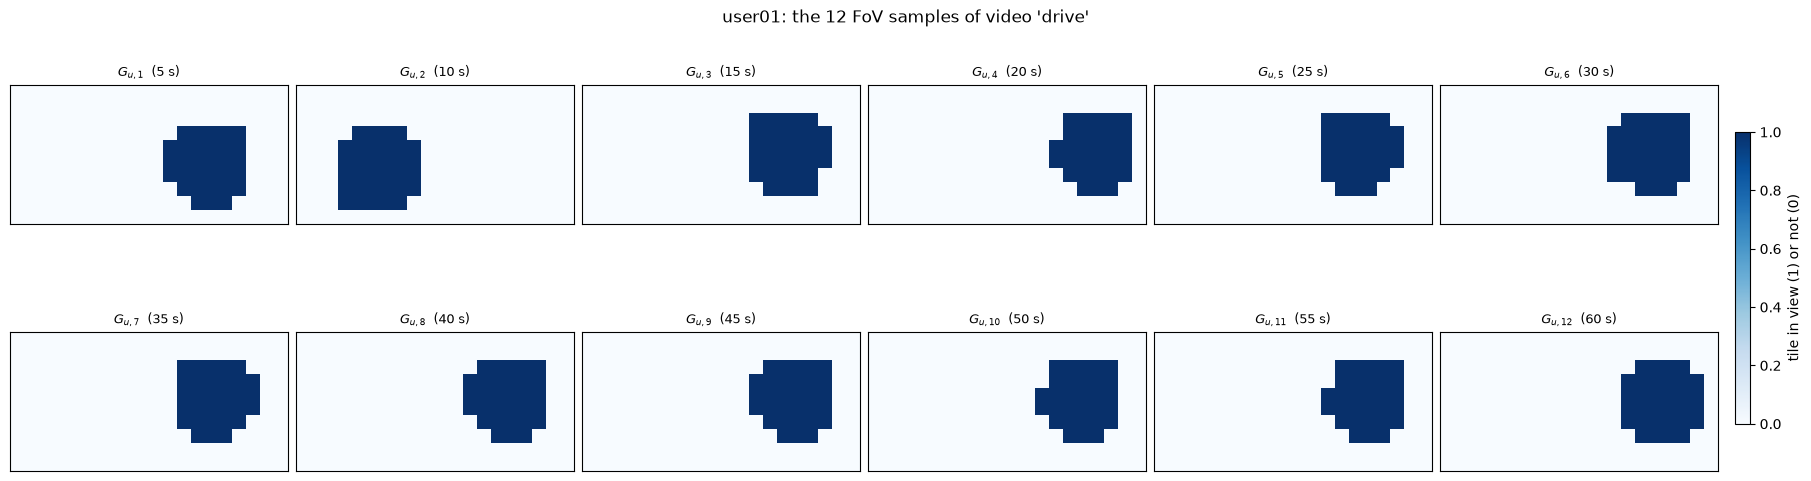

In [4]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

PLOT_K    = 12            # figures below look at the view at 5*PLOT_K seconds (valid: n+1 .. 12)
PLOT_USER = U_test[0]     # the viewer shown in detail
FIG_DIR   = "figures"     # PNG copies of the figures are saved here
os.makedirs(FIG_DIR, exist_ok=True)
assert cfg.n + 1 <= PLOT_K <= cfg.n_samples

CMAP = "Blues"            # one hue, light -> dark = tile probability 0 -> 1, same scale in every figure
IMSHOW = dict(cmap=CMAP, vmin=0, vmax=1, interpolation="nearest", aspect="equal")

def draw(ax, m, title=None, axes=False):
    # one 10x20 tile map: rows = latitude, columns = longitude (left and right edges are the same 360-degree seam)
    im = ax.imshow(m, **IMSHOW)
    if title: ax.set_title(title, fontsize=9)
    if axes:
        ax.set_xlabel("tile column (longitude)", fontsize=8); ax.set_ylabel("tile row (latitude)", fontsize=8)
        ax.tick_params(labelsize=7)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True)); ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    else:
        ax.set_xticks([]); ax.set_yticks([])
    return im

def user_grid(maps, title, fname, rows=5, cols=10):
    # one small map per viewer, 5 x 10 grid
    fig, axes = plt.subplots(rows, cols, figsize=(2.0 * cols, 1.25 * rows + 0.9), constrained_layout=True)
    for ax, u, m in zip(axes.ravel(), U, maps):
        im = draw(ax, m)
        ax.set_title(u.replace("user", "u"), fontsize=8, pad=2)
    fig.colorbar(im, ax=axes, shrink=0.6, pad=0.01, label="P(tile in view)")
    fig.suptitle(title, fontsize=12)
    fig.savefig(os.path.join(FIG_DIR, fname), dpi=130)
    plt.show()

fig, axes = plt.subplots(2, 6, figsize=(18, 5.2), constrained_layout=True)
for k, ax in enumerate(axes.ravel(), start=1):
    im = draw(ax, G[PLOT_USER][k - 1], f"$G_{{u,{k}}}$  ({5 * k} s)")
fig.colorbar(im, ax=axes, shrink=0.6, pad=0.01, label="tile in view (1) or not (0)")
fig.suptitle(f"{PLOT_USER}: the 12 FoV samples of video '{cfg.video}'", fontsize=12)
fig.savefig(os.path.join(FIG_DIR, "single_user_timeline.png"), dpi=150)
plt.show()

### 2.2 All 50 viewers at the same moment

The actual FoV $G_{u,k}$ of every viewer at $k$ = `PLOT_K`. Most viewers look at the same region of the video, with
a few looking elsewhere. This is why the crowd's combined frame $F_k$ is informative (see section 4.3).

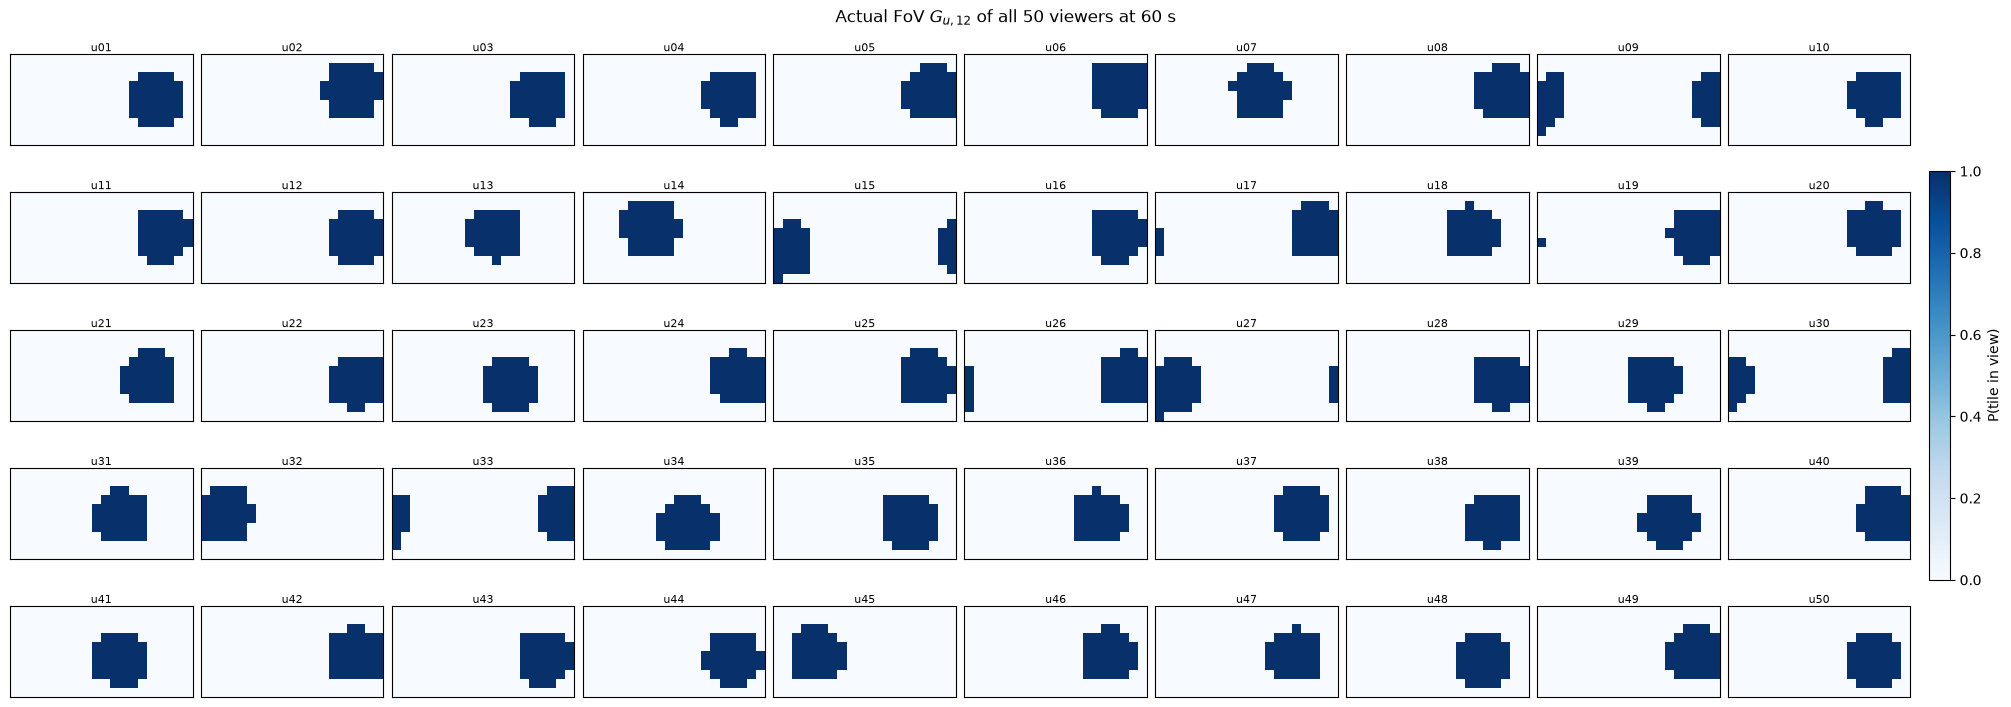

In [5]:
truth_k = np.stack([G[u][PLOT_K - 1] for u in U])        # (50, H, W)  actual G_{u,k}
user_grid(truth_k, f"Actual FoV $G_{{u,{PLOT_K}}}$ of all {len(U)} viewers at {5 * PLOT_K} s", "all_users_actual.png")

## 3. The predictor $f_\theta$ and its starting weights

The network has two convolution layers and a 1×1 convolution head, 3,073 weights in total. Padding wraps around in
longitude (the 360° seam of the video) and is zero in latitude.

| layer | operation | output channels |
|---|---|---|
| `conv1` | 3×3 convolution on the 5 input maps, ReLU | 16 |
| `conv2` | 3×3 convolution with dilation 2, ReLU | 16 |
| `head` | 1×1 convolution, sigmoid | 1 |

- **Input:** `(batch, H, W, n) = (batch, 10, 20, 5)`, the last 5 maps, oldest first.
- **Output:** `(batch, 10, 20)`, the probability that each tile is in view 5 s later.

Weights are initialised with Glorot-uniform kernels and zero biases, drawn with a fixed seed (`Cfg.seed`) so every run
starts from the same point. The head bias is set to the log-odds of the average tile occupancy, so the untrained
network already predicts the base rate.

In [6]:
class CircularPad(nn.Module):
    # Wrap columns (longitude), zero-pad rows (latitude). x is (batch, C, H, W).
    def __init__(self, p):
        super().__init__(); self.p = p
    def forward(self, x):
        p = self.p
        x = torch.cat([x[..., -p:], x, x[..., :p]], dim=3)
        return nn.functional.pad(x, (0, 0, p, p))


class Order5Predictor(nn.Module):
    def __init__(self, c=cfg):
        super().__init__()
        self.pad1  = CircularPad(1)
        self.conv1 = nn.Conv2d(c.n, c.width, 3)
        self.pad2  = CircularPad(2)
        self.conv2 = nn.Conv2d(c.width, c.width, 3, dilation=2)
        self.head  = nn.Conv2d(c.width, 1, 1)
        for conv in (self.conv1, self.conv2, self.head):
            nn.init.xavier_uniform_(conv.weight)
            nn.init.zeros_(conv.bias)
        nn.init.constant_(self.head.bias, float(np.log(BASE_RATE / (1 - BASE_RATE))))

    def forward(self, x):
        # x is (batch, H, W, n) like the numpy arrays; torch convs want (batch, n, H, W)
        h = x.permute(0, 3, 1, 2)
        h = torch.relu(self.conv1(self.pad1(h)))
        h = torch.relu(self.conv2(self.pad2(h)))
        return torch.sigmoid(self.head(h)).squeeze(1)          # G_hat_{u,k}: (batch, H, W)


def build_predictor(c=cfg):
    random.seed(c.seed); np.random.seed(c.seed); torch.manual_seed(c.seed)
    return Order5Predictor(c).to(DEVICE)


model = build_predictor()
print(f"parameters: {sum(p.numel() for p in model.parameters()):,}")


parameters: 3,073


## 4. Training

Each epoch takes one random 10-viewer group (70 pairs) and makes one plain gradient-descent step with learning rate
$\eta_e = a/(b+e)$.

The loss is $J = \lVert \hat G_{u,k} - G_{u,k}\rVert_2^2$, summed over the 200 tiles and averaged over the 70 pairs of
the epoch's group. There is one update per epoch: $\theta \leftarrow \theta - \eta_e\, \partial J/\partial\theta$.
No optimizer object is used; the update is written out in `gd_step`.

After the last epoch the RMSE is reported on all 350 pairs and on the held-out test group.

In [7]:
X_all_t, Y_all_t = torch.from_numpy(X_all), torch.from_numpy(Y_all)
X_by_user_t, Y_by_user_t = torch.from_numpy(X_by_user), torch.from_numpy(Y_by_user)
X_te_t, Y_te_t = torch.from_numpy(X_te), torch.from_numpy(Y_te)

def loss_fn(pred, y):
    return torch.mean(torch.sum(torch.square(pred - y), dim=(1, 2)))

def epoch_batch(s):
    idx = torch.tensor(s)
    return (X_by_user_t[idx].reshape(-1, cfg.H, cfg.W, cfg.n),
            Y_by_user_t[idx].reshape(-1, cfg.H, cfg.W))

def gd_step(Xb, Yb, lr):
    model.train()
    loss = loss_fn(model(Xb), Yb)
    params = list(model.parameters())
    grads = torch.autograd.grad(loss, params)
    with torch.no_grad():
        for v, g in zip(params, grads):
            v.sub_(lr * g)                         # theta <- theta - eta_e * dJ/dtheta
    return float(loss.detach())

@torch.no_grad()
def predict(X_t):
    model.eval()
    return model(X_t).cpu().numpy()

def rmse(p, y):
    return float(np.sqrt(np.mean((np.asarray(p) - np.asarray(y)) ** 2)))


t0 = time.time()
for e in range(1, cfg.epochs + 1):
    loss = gd_step(*epoch_batch(EPOCH_SETS[e - 1]), lr_at(e))
    if e == 1 or e % 100 == 0 or e == cfg.epochs:
        print(f"epoch {e:3d}  lr {lr_at(e):.5f}  loss {loss:7.3f}")

FINAL_ALL = rmse(predict(X_all_t), Y_all)
FINAL_TE  = rmse(predict(X_te_t), Y_te)
print(f"\nall 50 RMSE {FINAL_ALL:.4f}   test group RMSE {FINAL_TE:.4f}")

epoch   1  lr 0.06667  loss  25.929


epoch 100  lr 0.00100  loss  17.744


epoch 200  lr 0.00050  loss  15.336


epoch 300  lr 0.00033  loss  17.574


epoch 400  lr 0.00025  loss  16.362


epoch 494  lr 0.00020  loss  16.564

all 50 RMSE 0.2880   test group RMSE 0.2883


### 4.1 What the trained predictor outputs for one viewer

Top row: the five maps the predictor receives (oldest first). Bottom row: what the viewer actually looked at next, and
what the predictor says. The prediction is a soft heatmap: darker tiles are those the predictor considers more likely
to be in view. It is centred on the right region but blurred, because it is the best guess averaged over the possible
head movements in the next 5 s.

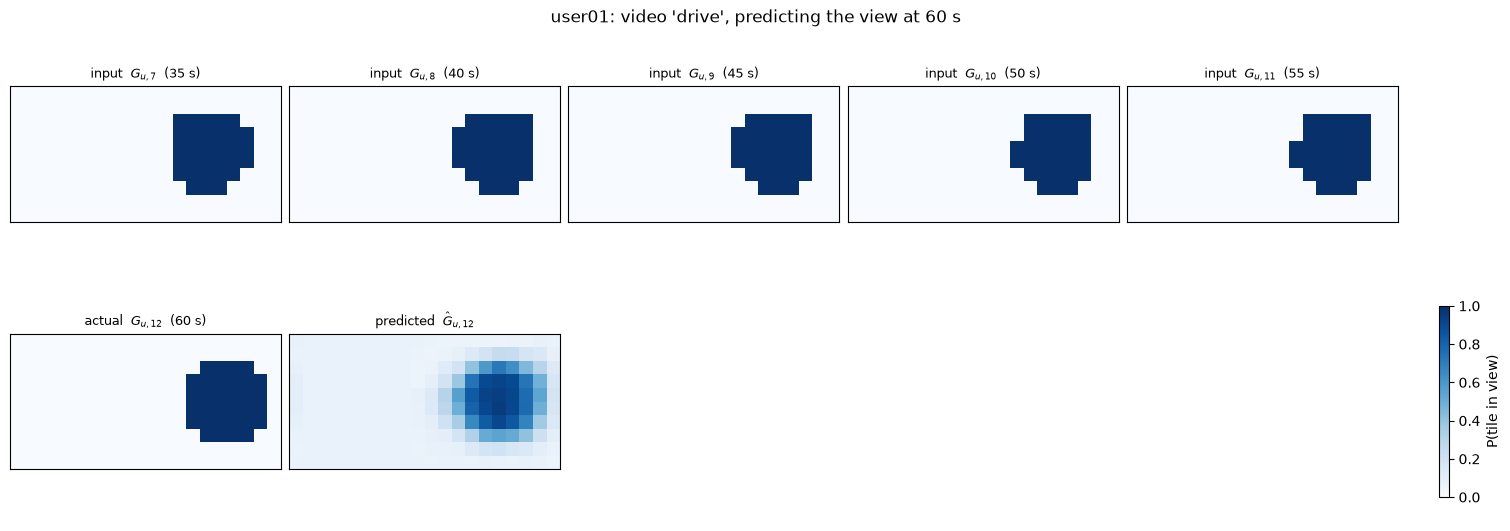

In [8]:
# predictions for every (viewer, k) pair, indexed [viewer, k - n - 1]
PRED = predict(X_all_t).reshape(len(U), cfg.pairs_per_user, cfg.H, cfg.W)
k_idx   = PLOT_K - cfg.n - 1
pred_k  = PRED[:, k_idx]                                 # (50, H, W)  predicted G_hat_{u,k}

ui = U.index(PLOT_USER)
fig, axes = plt.subplots(2, cfg.n, figsize=(3.0 * cfg.n, 5.2), constrained_layout=True)
for j in range(cfg.n):
    k_in = PLOT_K - cfg.n + j
    draw(axes[0, j], G[PLOT_USER][k_in - 1], f"input  $G_{{u,{k_in}}}$  ({5 * k_in} s)")
for ax in axes[1, 2:]:
    ax.axis("off")
draw(axes[1, 0], truth_k[ui], f"actual  $G_{{u,{PLOT_K}}}$  ({5 * PLOT_K} s)")
im = draw(axes[1, 1], pred_k[ui], f"predicted  $\\hat G_{{u,{PLOT_K}}}$")
fig.colorbar(im, ax=axes[1, 2:], shrink=0.8, label="P(tile in view)")
fig.suptitle(f"{PLOT_USER}: video '{cfg.video}', predicting the view at {5 * PLOT_K} s", fontsize=12)
fig.savefig(os.path.join(FIG_DIR, "single_user_prediction.png"), dpi=150)
plt.show()

### 4.2 All 50 viewers: predicted heatmaps

The predicted map of every viewer at the same moment, to compare with the actual maps in section 2.2. The predictor
was never told which viewer it is looking at; it only sees that viewer's last five maps.

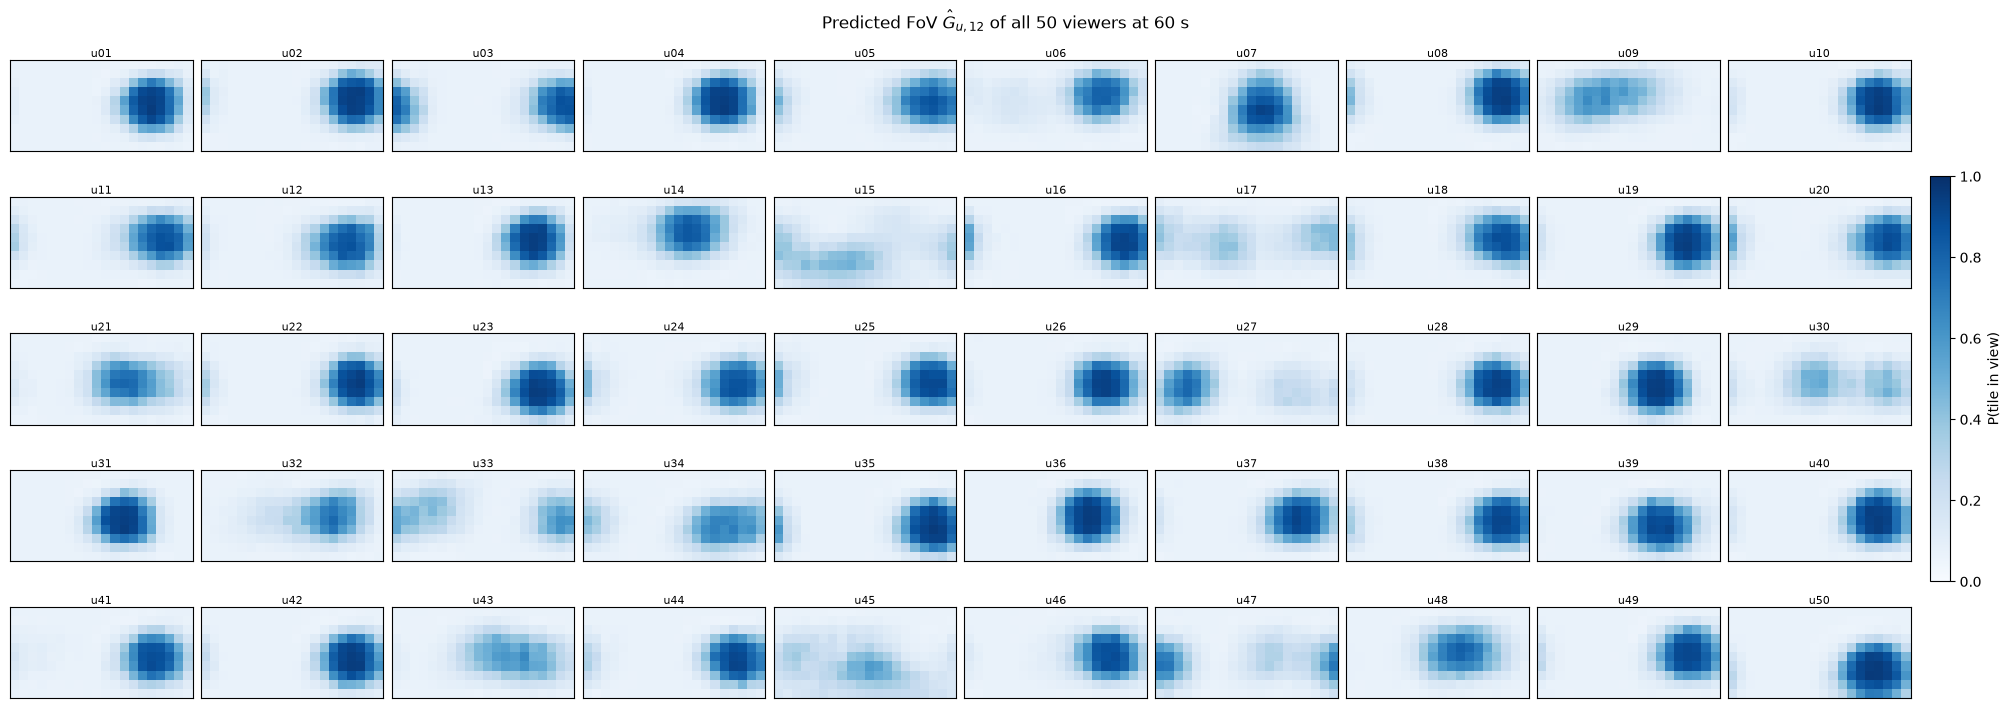

In [9]:
user_grid(pred_k, f"Predicted FoV $\\hat G_{{u,{PLOT_K}}}$ of all {len(U)} viewers at {5 * PLOT_K} s", "all_users_predicted.png")

### 4.3 The crowd heatmap

The crowd heatmap shows how many viewers look at each tile. Three versions, on the same scale:

1. **Actual crowd** $F_k = \frac{1}{\lvert\mathcal{U}\rvert}\sum_u G_{u,k}$: the real fraction of viewers who have each tile in view.
2. **Predicted crowd, averaged**: the mean of the 50 individual predictions $\hat G_{u,k}$ (each made from that viewer's own history).
3. **Predicted crowd, from the crowd**: $f_\theta$ applied once to the combined frames $F_{k-5}, \dots, F_{k-1}$. This is how
   the predictor is used at test time, when only the crowd's combined frame is available.

The last panel shows the difference between 3 and 1 (blue: over-predicted, red: under-predicted).

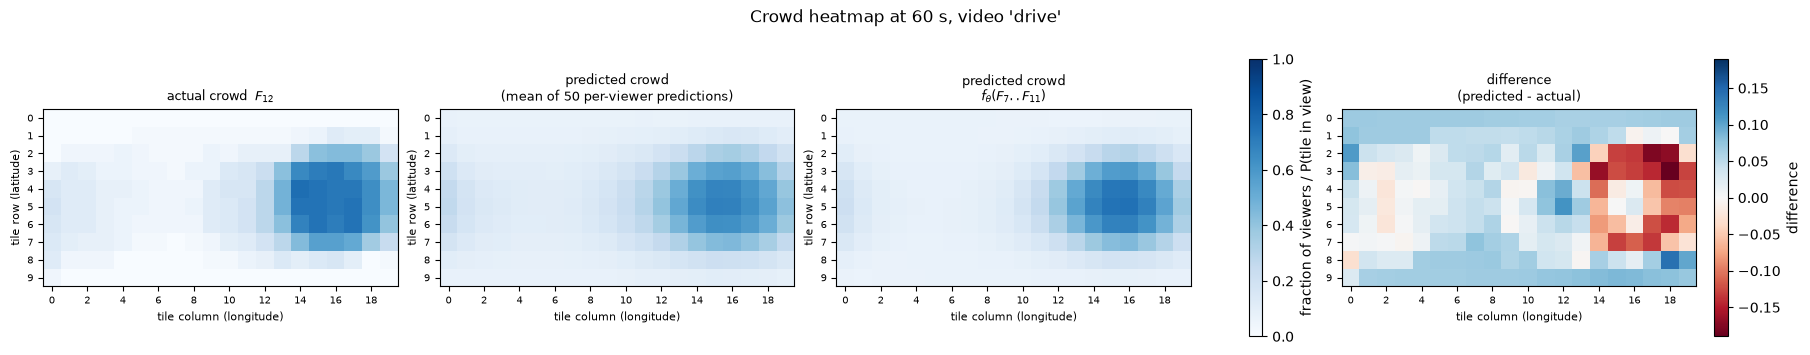

RMSE vs actual crowd: averaged per-viewer predictions 0.0791, predictor on crowd frames 0.0665


In [10]:
F = np.mean([G[u] for u in U], axis=0)                       # (12, H, W): combined frames F_k
F_in = np.stack([F[PLOT_K - cfg.n - 1 + j] for j in range(cfg.n)], axis=-1)[None].astype(np.float32)   # (1,H,W,n)
crowd_actual   = F[PLOT_K - 1]
crowd_avg_pred = pred_k.mean(axis=0)
crowd_pred     = predict(torch.from_numpy(F_in))[0]

fig, axes = plt.subplots(1, 4, figsize=(18, 3.6), constrained_layout=True)
draw(axes[0], crowd_actual,   f"actual crowd  $F_{{{PLOT_K}}}$", axes=True)
draw(axes[1], crowd_avg_pred, "predicted crowd\n(mean of 50 per-viewer predictions)", axes=True)
im = draw(axes[2], crowd_pred, f"predicted crowd\n$f_\\theta(F_{{{PLOT_K - cfg.n}}}..F_{{{PLOT_K - 1}}})$", axes=True)
fig.colorbar(im, ax=axes[:3], shrink=0.85, label="fraction of viewers / P(tile in view)")
diff = crowd_pred - crowd_actual
lim = float(np.abs(diff).max())
imd = axes[3].imshow(diff, cmap="RdBu", vmin=-lim, vmax=lim, interpolation="nearest")
axes[3].set_title("difference\n(predicted - actual)", fontsize=9)
axes[3].set_xlabel("tile column (longitude)", fontsize=8); axes[3].tick_params(labelsize=7)
axes[3].xaxis.set_major_locator(MaxNLocator(integer=True)); axes[3].yaxis.set_major_locator(MaxNLocator(integer=True))
fig.colorbar(imd, ax=axes[3], shrink=0.85, label="difference")
fig.suptitle(f"Crowd heatmap at {5 * PLOT_K} s, video '{cfg.video}'", fontsize=12)
fig.savefig(os.path.join(FIG_DIR, "crowd_heatmap.png"), dpi=150)
plt.show()

print(f"RMSE vs actual crowd: averaged per-viewer predictions {rmse(crowd_avg_pred, crowd_actual):.4f}, "
      f"predictor on crowd frames {rmse(crowd_pred, crowd_actual):.4f}")

## 5. Evaluation

The metric is the RMSE between predicted and actual maps, taken over all tiles and all pairs (lower is better). To judge
whether $f_\theta$ has learned anything, it is compared with two predictors that need no training:

- **average occupancy**: every tile gets the same value, the fraction of tiles in view over the whole dataset;
- **repeat last map**: the prediction for $G_{u,k}$ is simply $G_{u,k-1}$, i.e. the viewer is assumed not to move.

The numbers are reported on all 350 pairs and on the held-out test group (the 10 viewers that no epoch used).

In [11]:
def rmse_table(X, Y):
    return {
        "FoV predictor":           rmse(predict(torch.from_numpy(X)), Y),
        "average occupancy":       rmse(np.full_like(Y, BASE_RATE), Y),
        "repeat last map":         rmse(X[..., -1], Y),
    }

results = pd.DataFrame({"all 50 viewers": rmse_table(X_all, Y_all),
                        "test group":     rmse_table(X_te, Y_te)}).round(4)
print(results)
assert abs(rmse_table(X_all, Y_all)["FoV predictor"] - FINAL_ALL) < 1e-6   # same number as printed after training

                   all 50 viewers  test group
FoV predictor              0.2880      0.2883
average occupancy          0.3678      0.3683
repeat last map            0.3529      0.3292


## 6. Save the trained predictor

The predictor is trained, so its weights are set: it is put in `eval()` mode, every weight gets
`requires_grad = False`, and the checkpoint is saved for use in the VAE. The checkpoint is a plain dict:

| key | contents |
|---|---|
| `predictor` | the trained weights (`state_dict`, CPU tensors) |
| `cfg` | every field of `Cfg` (video, `n`, `W`, `H`, `width`, ...) |
| `base_rate` | mean tile occupancy over all 50 viewers |
| `U`, `U_test` | the 50 viewers, and the 10-viewer test group |
| `rmse` | final RMSE on all 50 viewers and on the test group |
| `input_shape`, `output_shape` | `(H, W, n)` and `(H, W)` |

In [12]:
model.eval()
for p_ in model.parameters():
    p_.requires_grad_(False)

torch.save({
    "predictor":    {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
    "cfg":          asdict(cfg),
    "base_rate":    BASE_RATE,
    "U":            U,
    "U_test":       U_test,
    "rmse":         {"all_50": FINAL_ALL, "test_group": FINAL_TE},
    "input_shape":  (cfg.H, cfg.W, cfg.n),
    "output_shape": (cfg.H, cfg.W),
    "torch_version": str(torch.__version__),     # plain str, so torch.load(weights_only=True) accepts it
}, WEIGHTS_FILE)

print(f"saved {WEIGHTS_FILE}  ({os.path.getsize(WEIGHTS_FILE) / 1024:.1f} KB)")
print("trainable weights left:", sum(p.numel() for p in model.parameters() if p.requires_grad))

saved ./predictor_weights_drive.pt  (16.3 KB)
trainable weights left: 0


## 7. Loading the pretrained predictor

The cell below loads `predictor_weights_drive.pt` and defines `predict_fov(x)`, which is how the VAE calls the predictor.
It does not read the dataset.

- **Input:** the last 5 FoV maps, oldest first, with values in [0, 1]: shape `(10, 20, 5)` or `(batch, 10, 20, 5)`.
  `stack_last5([m1, m2, m3, m4, m5])` builds it from five `(10, 20)` maps.
- **Output:** the predicted map, shape `(batch, 10, 20)`, with values in (0, 1).

In [13]:
import os
import numpy as np
import torch
from torch import nn

WEIGHTS_FILE = "predictor_weights_drive.pt"      # next to the notebook that loads it


class CircularPad(nn.Module):
    # Wrap columns (longitude), zero-pad rows (latitude). x is (batch, C, H, W).
    def __init__(self, p):
        super().__init__(); self.p = p
    def forward(self, x):
        p = self.p
        x = torch.cat([x[..., -p:], x, x[..., :p]], dim=3)
        return nn.functional.pad(x, (0, 0, p, p))


class Order5Predictor(nn.Module):
    def __init__(self, n=5, width=16):
        super().__init__()
        self.pad1  = CircularPad(1)
        self.conv1 = nn.Conv2d(n, width, 3)
        self.pad2  = CircularPad(2)
        self.conv2 = nn.Conv2d(width, width, 3, dilation=2)
        self.head  = nn.Conv2d(width, 1, 1)

    def forward(self, x):                                       # x: (batch, H, W, n), oldest map first
        h = x.permute(0, 3, 1, 2)
        h = torch.relu(self.conv1(self.pad1(h)))
        h = torch.relu(self.conv2(self.pad2(h)))
        return torch.sigmoid(self.head(h)).squeeze(1)          # (batch, H, W), values in (0, 1)


def load_pretrained_predictor(path=WEIGHTS_FILE, device="cpu"):
    ck = torch.load(path, map_location=device)
    net = Order5Predictor(ck["cfg"]["n"], ck["cfg"]["width"]).to(device)
    net.load_state_dict(ck["predictor"])
    net.eval()
    for p in net.parameters():
        p.requires_grad_(False)                                 # weights set: theta is never updated
    return net, ck


FOV_PREDICTOR, FOV_CK = load_pretrained_predictor()
FOV_CFG = FOV_CK["cfg"]


def stack_last5(maps):
    # five (H, W) maps, oldest first  ->  one (H, W, 5) input
    return np.stack(maps, axis=-1).astype(np.float32)


@torch.no_grad()
def predict_fov(x):
    # x: (H, W, n) or (batch, H, W, n), oldest map first  ->  (batch, H, W) numpy, P(tile in view 5 s later)
    x = torch.as_tensor(np.asarray(x, np.float32), device=next(FOV_PREDICTOR.parameters()).device)
    if x.dim() == 3:
        x = x.unsqueeze(0)
    return FOV_PREDICTOR(x).cpu().numpy()


print(f"loaded pretrained FoV predictor: video '{FOV_CFG['video']}', order n = {FOV_CFG['n']}, "
      f"grid {FOV_CFG['H']} x {FOV_CFG['W']}, input {tuple(FOV_CK['input_shape'])} -> output {tuple(FOV_CK['output_shape'])}")
print(f"trainable weights: {sum(p.numel() for p in FOV_PREDICTOR.parameters() if p.requires_grad)}   "
      f"RMSE all 50 {FOV_CK['rmse']['all_50']:.4f}, test group {FOV_CK['rmse']['test_group']:.4f}")

loaded pretrained FoV predictor: video 'drive', order n = 5, grid 10 x 20, input (10, 20, 5) -> output (10, 20)
trainable weights: 0   RMSE all 50 0.2880, test group 0.2883


### Check: the loader reproduces the trained model

The loader above has just read the file `predictor_weights_drive.pt`. The cell below checks that its predictions are
identical to those of the model trained in section 4, and shows the output shape for a single input.

In [14]:
same = np.array_equal(predict_fov(X_all), predict(X_all_t))
print(f"loader predictions == trained model predictions on all {len(X_all)} pairs: {same}")
print(f"RMSE through the loader: all 50 {rmse(predict_fov(X_all), Y_all):.4f}, test group {rmse(predict_fov(X_te), Y_te):.4f}")
one = predict_fov(stack_last5([G[U_test[0]][k] for k in range(5)]))     # G_1..G_5 -> G_hat_6 for one viewer
print(f"single input -> output shape {one.shape}, range [{one.min():.3f}, {one.max():.3f}]")
assert same

loader predictions == trained model predictions on all 350 pairs: True
RMSE through the loader: all 50 0.2880, test group 0.2883
single input -> output shape (1, 10, 20), range [0.055, 0.899]
